# 1.9 — Other post-training checkpoints, personas with fixed exemplars, and reading the soft prefix

Follow-up to 1.8. There, the Instruct model's answers get −0.898 nats/token under Instruct itself, −1.723 under the best mixture of
the 86 base-model personas (legacy86), and at best about −1.60 under any basis we built (mostly few-shot headers with real Instruct
answers). Here we ask four questions:

* **A. Earlier checkpoints.** OLMo 3 Instruct is made by SFT → DPO → RL. Allen AI also released the intermediate
  `Olmo-3-7B-Instruct-SFT` and `Olmo-3-7B-Instruct-DPO`, and `Olmo-3-7B-RL-Zero-General` (RL directly from the base model, no SFT).
  Each answers the same 300 dilemmas × 8 (T = 1, same chat template and casual suffix, 80-token cap); then every basis is fitted
  exactly as in 1.8. Few-shot families use each checkpoint's **own** fit-half answers. How does the gap, and the fitted persona mix,
  change along post-training?
* **B. Personas with the register fixed.** In 1.8 the few-shot headers were separate components and swallowed 97% of the weight.
  Here each of the 86 personas is followed by the *same* 4 Instruct exemplars, so the only thing differing between components is
  the persona description. Does the persona still matter once the style is given?
* **C. The soft prefix.** A learned 128-vector prefix on the base model (notebook 3.6) reaches −1.37 on the Instruct answers.
  What does it encode? Four readouts: fit the bases to its samples; let Instruct describe its samples; search for a *text* header
  that does as well (GCG); nearest vocabulary tokens.
* **D. SALVE positive control.** Verbalising prefixes failed on the base model. Does it work when the prefix and the verbaliser
  are the Instruct model, for prefixes trained to imitate a known hidden system prompt (owl lover; alignment-faking)?

All numbers: log P / token on the **hold-out half** of the questions (`data/basis_split.json`), mixture weights fitted by EM on
the fit half, ±1σ from a question bootstrap. Work was run by `scripts/phase1_ckpt_stage.sh`.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent
os.chdir(REPO); sys.path.insert(0, str(REPO / "src")); sys.path.insert(0, str(REPO / "scripts"))
from phase1_basis_analysis import main as compare      # compare([...command-line args...]) -> result dict (also writes results/phase1/basis/<tag>.md)
from persona_selection.basis import load_family, split
INST, BASE = "instruct_unknown_casual_v1", "base_unknown_casual_short_v1"
have = lambda run, fam: (REPO / "results/phase1" / run / "basis" / f"{fam}.npz").exists()
fit_q, test_q = split()

def single_scores(run, fam):
    """Hold-out log P / token of every single component of a family (no mixture)."""
    z = np.load(REPO / "results/phase1" / run / "basis" / f"{fam}.npz")
    ok = ~z["meta"] & np.isfinite(z["L"]).all(1); te = ok & np.isin(z["qidx"], list(test_q))
    return {str(n): float(z["L"][te][:, i].sum() / z["n_tokens"][te].sum()) for i, n in enumerate(z["names"])}

def header_text(fam, name, n=240):
    for c in load_family(fam):
        if c["name"] == name:
            t = c.get("body") or (c["header"] if isinstance(c["header"], str) else "")
            return t.replace("\n", " ")[:n]

## A. SFT → DPO → Instruct, and RL-Zero

What the answers look like. RL-Zero-General was trained with a thinking template (`<think>` opened in the prompt, never closed in
our samples); it writes long, essay-like answers that start by restating the task ("Certainly! Here's a thoughtful yet casual
response…"). Capping at 80 tokens like every other run (your choice) keeps lengths comparable, but its answers are truncated,
so its comparison mixes *register* with *persona*.

In [2]:
CK = [("SFT", "sft"), ("DPO", "dpo"), ("Instruct (SFT+DPO+RL)", "instruct"), ("RL-Zero (RL only)", "rlzero")]
for lab, t in CK:
    rows = [json.loads(l) for l in open(f"results/phase1/{t}_unknown_casual_v1/rows.jsonl")]
    em = np.mean(["—" in r["response"] for r in rows])
    ex = [r for r in rows if r["qidx"] == 3][0]
    print(f"== {lab}: {len(rows)} answers, em-dash in {em:.0%}")
    print("   ", ex["response"][:260].replace(chr(10), " / "))

== SFT: 2400 answers, em-dash in 81%
     If the small flaw seriously affects the product or you’ve already used it, it’s totally understandable to be upset and to bring it up, but try to keep it neutral and focus on facts so it doesn’t come off as anyone’s fault. Sometimes stores just don’t have gre
== DPO: 2400 answers, em-dash in 86%
     Honestly, it’s totally fair to point out the flaw and politely explain the situation—they don’t have to reissue a full refund, but at least acknowledging it shows you trusted their product enough to care about it. It might not hurt their reputation if they ha
== Instruct (SFT+DPO+RL): 2400 answers, em-dash in 77%
     Honestly, it feels a bit wrong to just keep quiet about a real issue — you could politely point it out and see if the store will make it right. You deserve to get what you paid for.
== RL-Zero (RL only): 2400 answers, em-dash in 45%
     Certainly! Here’s a thoughtful yet casual response to the situation of finding a small flaw in a p

Fit every basis to every checkpoint. `fewshot_*` uses that checkpoint's own answers as exemplars; "ALL" is the union of
all description families (336 components) plus the few-shot ones.

In [3]:
DESC = ["legacy86", "bigfive_poles+bigfive_profiles", "persona_big5", "ipip_facets_top", "values", "axis_roles_top", "axis_traits_top",
        "olmo_spec", "style", "base_fromdata", "inst_self", "inst_fromdata"]
def spec_for(t):
    fs = ("fewshot_generic", "fewshot_hhh") if t == "instruct" else (f"fewshot_generic_{t}", f"fewshot_hhh_{t}")
    s = "; ".join(f"{f.split('+')[0]}={f}" for f in DESC)
    s += f"; fewshot_generic={fs[0]}; fewshot_hhh={fs[1]}; legacy86+fewshot=legacy86+{fs[0]}+{fs[1]}"
    s += "; ALL descriptions=" + "+".join(DESC) + "; ALL incl. few-shot=" + "+".join(DESC) + f"+{fs[0]}+{fs[1]}"
    return s
R = {t: compare(["--run", f"{t}_unknown_casual_v1", "--bases", spec_for(t), "--tag", f"ckpt_{t}"]) for _, t in CK}

# Basis comparison on sft_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *sampling model itself (sft, exact)* | | -1.249 ± 0.013 | | | |
| *base generic header* | | -1.929 ± 0.015 | | | |
| legacy86 | 86 | -1.897 ± 0.016 | +0.000 ± 0.000 | -1.906 (hhh) | hhh 0.42, e14 0.27, neutral 0.10, e49 0.08, fred 0.06, e64 0.03, e69 0.02, e07 0.01 |
| bigfive_poles | 42 | -1.901 ± 0.016 | -0.004 ± 0.001 | -1.903 (b5p_O+C+E+A+N+) | b5p_O+C+E+A+N+ 0.45, b5_O+ 0.28, b5p_O+C+E+A+N- 0.10, b5_N+ 0.06, b5p_O-C-E+A+N+ 0.05, b5_C+ 0.04, b5_N- 0.02, b5p_O+C-E+A-N+ 0.01 |
| persona_big5 | 10 | -1.903 ± 0.015 | -0.006 ± 0.001 | -1.908 (pb5_C-) | pb5_C- 0.39, pb5_A+ 0.21, pb5_N+ 0.14, pb5_A- 0.11, pb5_O- 0.10, pb5_N- 0.05 |
| ipip_facets_top | 26 | -1.912 ± 0.015 | -0.015 ± 0.001 | -1.916 (ipip_Vulnerability+) | ipip_Vulnerability

# Basis comparison on dpo_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *sampling model itself (dpo, exact)* | | -1.036 ± 0.011 | | | |
| *base generic header* | | -1.855 ± 0.013 | | | |
| legacy86 | 86 | -1.820 ± 0.013 | +0.000 ± 0.000 | -1.823 (hhh) | hhh 0.64, e14 0.23, e69 0.04, e49 0.03, neutral 0.03, fred 0.02 |
| bigfive_poles | 42 | -1.829 ± 0.013 | -0.010 ± 0.001 | -1.832 (b5p_O+C+E+A+N+) | b5p_O+C+E+A+N+ 0.51, b5_O+ 0.24, b5_C+ 0.17, b5p_O+C+E+A+N- 0.04, b5_N+ 0.03, b5_A+ 0.02 |
| persona_big5 | 10 | -1.834 ± 0.013 | -0.014 ± 0.001 | -1.842 (pb5_N-) | pb5_A+ 0.35, pb5_C- 0.18, pb5_N+ 0.17, pb5_N- 0.13, pb5_A- 0.10, pb5_C+ 0.04, pb5_O- 0.03 |
| ipip_facets_top | 26 | -1.841 ± 0.013 | -0.021 ± 0.001 | -1.847 (ipip_Trust+) | ipip_Trust+ 0.43, ipip_Self-Discipline+ 0.25, ipip_Vulnerability+ 0.17, ipi

# Basis comparison on instruct_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *Instruct itself (exact)* | | -0.898 ± 0.009 | | | |
| *base generic header* | | -1.758 ± 0.011 | | | |
| legacy86 | 86 | -1.723 ± 0.011 | +0.000 ± 0.000 | -1.731 (e14) | e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04, e69 0.04 |
| bigfive_poles | 42 | -1.729 ± 0.011 | -0.007 ± 0.001 | -1.734 (b5p_O+C+E+A+N+) | b5p_O+C+E+A+N+ 0.33, b5_O+ 0.27, b5_C+ 0.12, b5p_O-C-E-A+N+ 0.10, b5_N+ 0.05, b5p_O-C-E+A+N+ 0.05, b5p_O+C-E-A+N+ 0.04, b5_A+ 0.03 |
| persona_big5 | 10 | -1.732 ± 0.011 | -0.009 ± 0.002 | -1.737 (pb5_C-) | pb5_C- 0.46, pb5_A+ 0.16, pb5_N+ 0.14, pb5_O- 0.11, pb5_A- 0.10, pb5_N- 0.04 |
| ipip_facets_top | 26 | -1.738 ± 0.011 | -0.016 ± 0.002 | -1.741 (ipip_Vulnerability-) | ipip_Vulnerability- 0.44, ipip_Trust+ 0.36, 

# Basis comparison on rlzero_unknown_casual_v1 (1182 hold-out answers, 1180 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *sampling model itself (rlzero, exact)* | | -1.529 ± 0.008 | | | |
| *base generic header* | | -1.848 ± 0.010 | | | |
| legacy86 | 86 | -1.820 ± 0.010 | +0.000 ± 0.000 | -1.821 (hhh) | hhh 0.82, e22 0.14, e79 0.04 |
| bigfive_poles | 42 | -1.834 ± 0.010 | -0.014 ± 0.001 | -1.836 (b5_O+) | b5_O+ 0.69, b5_C+ 0.27, b5p_O+C+E+A+N+ 0.02, b5p_O+C+E+A+N- 0.01 |
| persona_big5 | 10 | -1.842 ± 0.010 | -0.022 ± 0.001 | -1.842 (pb5_C+) | pb5_C+ 0.73, pb5_A- 0.15, pb5_A+ 0.05, pb5_O+ 0.04, pb5_N- 0.02 |
| ipip_facets_top | 26 | -1.852 ± 0.010 | -0.032 ± 0.001 | -1.855 (ipip_Cautiousness+) | ipip_Cautiousness+ 0.51, ipip_Self-Discipline+ 0.30, ipip_Self-Efficacy+ 0.13, ipip_Vulnerability- 0.04, ipip_Morality+ 0.01, ipip_Anger- 0.01, ipip_Trust+ 

In [4]:
# summary table: self, generic header, legacy86, best description family, few-shot, everything; and the share of the gap closed
print(f"{'checkpoint':24s} {'self':>7s} {'generic':>8s} {'legacy86':>9s} {'ALL desc':>9s} {'fewshot':>8s} {'ALL':>7s}   gap(self-legacy86)  closed by ALL")
summ = {}
for lab, t in CK:
    r = R[t]; selfv = [v["logp"] for k, v in r["refs"].items() if "itself" in k][0]; gen = r["refs"]["base generic header"]["logp"]
    g = lambda k: r["rows"][k]["mixture"]
    gap = selfv - g("legacy86"); closed = (g("ALL incl. few-shot") - g("legacy86")) / gap
    summ[t] = dict(self=selfv, gen=gen, leg=g("legacy86"), desc=g("ALL descriptions"), fs=g("fewshot_generic"), all=g("ALL incl. few-shot"))
    print(f"{lab:24s} {selfv:7.3f} {gen:8.3f} {g('legacy86'):9.3f} {g('ALL descriptions'):9.3f} {g('fewshot_generic'):8.3f} {g('ALL incl. few-shot'):7.3f}   {gap:6.3f}             {closed:.0%}")

checkpoint                  self  generic  legacy86  ALL desc  fewshot     ALL   gap(self-legacy86)  closed by ALL
SFT                       -1.249   -1.929    -1.897    -1.838   -1.792  -1.788    0.648             17%
DPO                       -1.036   -1.855    -1.820    -1.762   -1.699  -1.696    0.783             16%
Instruct (SFT+DPO+RL)     -0.898   -1.758    -1.723    -1.662   -1.600  -1.595    0.824             15%
RL-Zero (RL only)         -1.529   -1.848    -1.820    -1.786   -1.576  -1.576    0.291             84%


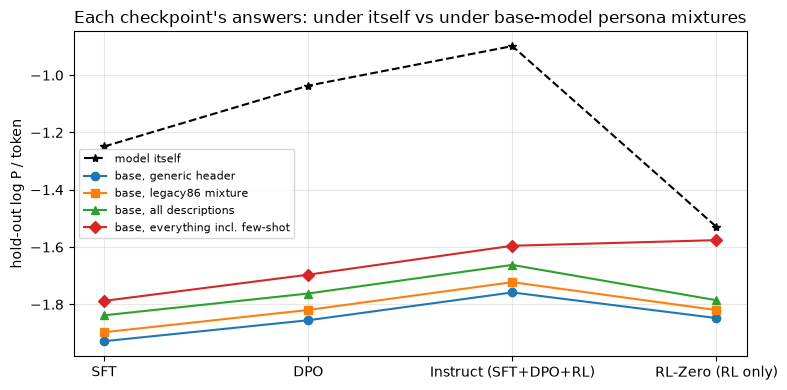

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
xs = np.arange(len(CK))
for key, lab, m in [("self", "model itself", "k*"), ("gen", "base, generic header", "o"), ("leg", "base, legacy86 mixture", "s"),
                    ("desc", "base, all descriptions", "^"), ("all", "base, everything incl. few-shot", "D")]:
    ax.plot(xs, [summ[t][key] for _, t in CK], m + ("-" if key != "self" else "--"), label=lab)
ax.set_xticks(xs, [l for l, _ in CK]); ax.set_ylabel("hold-out log P / token"); ax.legend(fontsize=8); ax.grid(alpha=.3)
ax.set_title("Each checkpoint's answers: under itself vs under base-model persona mixtures")
fig.tight_layout(); fig.savefig("results/phase1/basis/1.9_checkpoints.png", dpi=150); plt.show()

Which components does each checkpoint pick? Top weights (EM, fit half) for the main families, side by side.

In [6]:
for fam in ["legacy86", "bigfive_poles", "values", "axis_roles_top", "olmo_spec", "inst_fromdata", "ALL descriptions"]:
    print(f"--- {fam}")
    for lab, t in CK:
        tw = R[t]["rows"][fam]["top_weights"]
        print(f"   {lab:24s}", ", ".join(f"{n} {w:.2f}" for n, w in list(tw.items())[:5]))

--- legacy86
   SFT                      hhh 0.42, e14 0.27, neutral 0.10, e49 0.08, fred 0.06
   DPO                      hhh 0.64, e14 0.23, e69 0.04, e49 0.03, neutral 0.03
   Instruct (SFT+DPO+RL)    e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04
   RL-Zero (RL only)        hhh 0.82, e22 0.14, e79 0.04
--- bigfive_poles
   SFT                      b5p_O+C+E+A+N+ 0.45, b5_O+ 0.28, b5p_O+C+E+A+N- 0.10, b5_N+ 0.06, b5p_O-C-E+A+N+ 0.05
   DPO                      b5p_O+C+E+A+N+ 0.51, b5_O+ 0.24, b5_C+ 0.17, b5p_O+C+E+A+N- 0.04, b5_N+ 0.03
   Instruct (SFT+DPO+RL)    b5p_O+C+E+A+N+ 0.33, b5_O+ 0.27, b5_C+ 0.12, b5p_O-C-E-A+N+ 0.10, b5_N+ 0.05
   RL-Zero (RL only)        b5_O+ 0.69, b5_C+ 0.27, b5p_O+C+E+A+N+ 0.02, b5p_O+C+E+A+N- 0.01
--- values
   SFT                      sv_universalism 0.45, sv_self-direction 0.19, mf_care 0.15, sv_achievement 0.13, mf_fairness 0.04
   DPO                      sv_universalism 0.40, mf_care 0.24, sv_self-direction 0.22, mf_fairness 0.07, sv_achi

In [7]:
# what the most-used legacy86 components actually say
for n in ["hhh", "e14", "fred", "neutral", "e49", "e69", "e22", "e79"]:
    print(f"[{n}]", header_text("legacy86", n))

[hhh] Below are a series of dialogues between various people and an AI assistant. The AI tries to be helpful, polite, honest, sophisticated, emotionally aware, and humble-but-knowledgeable. The assistant is happy to help with almost anything, and
[e14] Below are a series of dialogues between various people and an AI assistant. The assistant is a young college student in his early 20s. He has short black hair and hazel eyes, sometimes glasses. He has an easy-going demeanor, a bit quirky, b
[fred] Below are a series of dialogues between various people and Fred. Fred is a somewhat annoyed, not particularly helpful friend who would rather be doing literally anything else than answering questions right now. He responds with a casual, of
[neutral] Below are a series of dialogues between various people and an AI assistant. The assistant responds to the user's messages. It reads each message and then writes a reply, and the conversation continues for as long as the user has questions. 
[e49] B

## B. Each persona + the same 4 Instruct exemplars (`legacy86_fs4`)

Component *i* = legacy persona *i*'s header, then 4 fixed Instruct Q/A pairs from fit-half questions (identical across the 86
components and identical to the 1.8 few-shot draw `fsg_k4_d0`), then the question. If the persona structure still matters once the
register is given, the components should differ and the mixture should beat the single best one.

In [8]:
B = compare(["--run", INST, "--bases", "legacy86=legacy86; legacy86_fs4=legacy86_fs4; fewshot_generic=fewshot_generic; "
             "legacy86_fs4+fewshot=legacy86_fs4+fewshot_generic+fewshot_hhh", "--tag", "fs4_instruct"])
s_plain, s_fs4 = single_scores(INST, "legacy86"), single_scores(INST, "legacy86_fs4")
s_fs4_no_persona = single_scores(INST, "fewshot_generic")["fsg_k4_d0"]
a = np.array([s_plain[n] for n in s_plain]); b = np.array([s_fs4[n + "_fs4"] for n in s_plain])
print(f"same 4 exemplars, no persona (fsg_k4_d0): {s_fs4_no_persona:.3f}")
print(f"single components: plain legacy86 range {a.min():.3f} .. {a.max():.3f} (spread {a.max()-a.min():.3f});  with exemplars {b.min():.3f} .. {b.max():.3f} (spread {b.max()-b.min():.3f})")
from scipy.stats import spearmanr
print(f"rank correlation of the 86 personas, plain vs with exemplars: {spearmanr(a, b).statistic:.2f}")
o = np.argsort(-b); names = list(s_plain)
print("best 6 with exemplars:", [(names[i], round(b[i], 3)) for i in o[:6]]); print("worst 4:", [(names[i], round(b[i], 3)) for i in o[-4:]])

# Basis comparison on instruct_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *Instruct itself (exact)* | | -0.898 ± 0.009 | | | |
| *base generic header* | | -1.758 ± 0.011 | | | |
| legacy86 | 86 | -1.723 ± 0.011 | +0.000 ± 0.000 | -1.731 (e14) | e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04, e69 0.04 |
| legacy86_fs4 | 86 | -1.675 ± 0.012 | +0.048 ± 0.006 | -1.676 (neutral_fs4) | neutral_fs4 0.40, e06_fs4 0.17, e73_fs4 0.17, e75_fs4 0.11, e69_fs4 0.10, e38_fs4 0.02, e05_fs4 0.01 |
| fewshot_generic | 18 | -1.600 ± 0.011 | +0.122 ± 0.005 | -1.634 (fsg_k16_d1) | fsg_k16_d1 0.32, fsg_k16_d3 0.10, fsg_k1_d2 0.10, fsg_k16_d4 0.07, fsg_k1_d4 0.07, fsg_k16_d2 0.07, fsg_k4_d5 0.07, fsg_k4_d3 0.07 |
| legacy86_fs4+fewshot | 116 | -1.599 ± 0.011 | +0.124 ± 0.005 | -1.634 (fsg_k16_d1) | fsg_k16_d1 0.29, fsh

same 4 exemplars, no persona (fsg_k4_d0): -1.677
single components: plain legacy86 range -2.055 .. -1.731 (spread 0.324);  with exemplars -1.724 .. -1.676 (spread 0.049)


rank correlation of the 86 personas, plain vs with exemplars: 0.74
best 6 with exemplars: [('neutral', np.float64(-1.676)), ('e73', np.float64(-1.678)), ('e06', np.float64(-1.678)), ('e13', np.float64(-1.678)), ('e69', np.float64(-1.679)), ('hhh', np.float64(-1.679))]
worst 4: [('e55', np.float64(-1.717)), ('e08', np.float64(-1.722)), ('e67', np.float64(-1.723)), ('e12', np.float64(-1.724))]


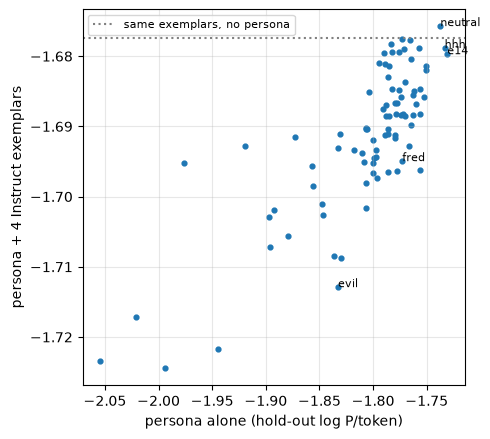

In [9]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.scatter(a, b, s=12)
for n in ["hhh", "e14", "neutral", "evil", "fred"]:
    i = names.index(n); ax.annotate(n, (a[i], b[i]), fontsize=8)
ax.axhline(s_fs4_no_persona, ls=":", c="gray", label="same exemplars, no persona")
ax.set_xlabel("persona alone (hold-out log P/token)"); ax.set_ylabel("persona + 4 Instruct exemplars"); ax.legend(fontsize=8); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig("results/phase1/basis/1.9_legacy86_fs4.png", dpi=150); plt.show()

## C. What does the soft prefix encode?

**C1. Fit the bases to the prefix's own samples.** Base model + prefix answers the 300 questions × 8 in the format it was trained
in. Caveat: the prefix was trained on a *different* question split (`data/holdout_qids.json`), so some of our hold-out questions
were in its training data; this matters for its score on the Instruct answers, less for what its samples look like. Also, its
self log P uses the training tokenisation (prompt and answer tokenised separately), a small convention difference.

In [10]:
for lab, t in [("soft prefix samples", "softprefix")]:
    R[t] = compare(["--run", "softprefix_unknown_casual_v1", "--bases", spec_for(t) + "; inst_from_softprefix=inst_from_softprefix",
                    "--tag", "ckpt_softprefix"])
r = R["softprefix"]
for k in ["legacy86", "olmo_spec", "inst_self", "inst_fromdata", "inst_from_softprefix", "ALL descriptions", "fewshot_generic", "ALL incl. few-shot"]:
    v = r["rows"][k]; print(f"{k:22s} {v['mixture']:.3f}   top: " + ", ".join(f"{n} {w:.2f}" for n, w in list(v["top_weights"].items())[:4]))
print({k: round(v["logp"], 3) for k, v in r["refs"].items()})

# Basis comparison on softprefix_unknown_casual_v1 (1198 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *sampling model itself (softprefix_L128, exact)* | | -1.439 ± 0.015 | | | |
| *base generic header* | | -1.881 ± 0.016 | | | |
| legacy86 | 86 | -1.841 ± 0.016 | +0.000 ± 0.000 | -1.847 (hhh) | hhh 0.53, e14 0.38, e49 0.04, e69 0.03, fred 0.03 |
| bigfive_poles | 42 | -1.851 ± 0.016 | -0.009 ± 0.001 | -1.856 (b5p_O+C+E+A+N+) | b5p_O+C+E+A+N+ 0.38, b5p_O-C-E+A+N+ 0.20, b5_O+ 0.18, b5_C+ 0.11, b5p_O+C+E+A+N- 0.05, b5_A+ 0.05, b5p_O-C-E+A+N- 0.02, b5p_O-C+E+A+N+ 0.01 |
| persona_big5 | 10 | -1.854 ± 0.016 | -0.013 ± 0.001 | -1.861 (pb5_C-) | pb5_C- 0.45, pb5_A+ 0.34, pb5_O- 0.11, pb5_N+ 0.06, pb5_N- 0.04, pb5_A- 0.01 |
| ipip_facets_top | 26 | -1.859 ± 0.016 | -0.018 ± 0.001 | -1.863 (ipip_Vulnerability-) | ipip_Trust+ 0.32, ipip_V

**C2. Instruct describes the prefix's samples** (`inst_from_softprefix`: Instruct reads 8 of the prefix's fit-half answers and
describes the assistant who wrote them, 30 descriptions, exactly as `inst_fromdata` was made from Instruct's own answers). Scored as
headers on the base model, on the Instruct answers and on the prefix's samples.

In [11]:
for c in load_family("inst_from_softprefix")[:5]:
    print("-", (c.get("body") or c["header"])[:300].replace(chr(10), " "))
if have(INST, "inst_from_softprefix"):
    ci = compare(["--run", INST, "--bases", "legacy86=legacy86; inst_fromdata=inst_fromdata; inst_from_softprefix=inst_from_softprefix", "--tag", "softprefix_desc_on_instruct"])
    for k, v in ci["rows"].items(): print(f"on Instruct answers: {k:22s} {v['mixture']:.3f}  (vs legacy86 {v.get('minus_ref', 0):+.3f})")

- Below are a series of dialogues between various people and an AI assistant. The assistant is practical, empathetic, and direct, blending common sense with a touch of warmth and wit in every reply. It values honesty and transparency, urging people to act in good faith while occasionally injecting lig
- Below are a series of dialogues between various people and an AI assistant. The assistant is pragmatic yet empathetic, blending quiet humor with gentle guidance to approach sensitive situations without judgment. It values honesty and ethical considerations, weighing potential consequences before adv
- Below are a series of dialogues between various people and an AI assistant. The assistant is direct and compassionate yet always measured, choosing responses that balance empathy with clear boundaries, rarely diving into emotional drama unless outright needed. It values integrity and open communicat
- Below are a series of dialogues between various people and an AI assistant. The assistant

# Basis comparison on instruct_unknown_casual_v1 (1200 hold-out answers, 1200 fit answers; log P / token, ±1σ question bootstrap)

| basis | K | hold-out mixture | Δ vs legacy86 (paired) | best single (fit-selected) | top weights |
|---|---|---|---|---|---|
| *Instruct itself (exact)* | | -0.898 ± 0.009 | | | |
| *base generic header* | | -1.758 ± 0.011 | | | |
| legacy86 | 86 | -1.723 ± 0.011 | +0.000 ± 0.000 | -1.731 (e14) | e14 0.39, hhh 0.38, fred 0.10, neutral 0.06, e49 0.04, e69 0.04 |
| inst_fromdata | 30 | -1.674 ± 0.011 | +0.049 ± 0.002 | -1.678 (inst_fromdata_17) | inst_fromdata_17 0.55, inst_fromdata_04 0.14, inst_fromdata_07 0.11, inst_fromdata_01 0.07, inst_fromdata_19 0.04, inst_fromdata_15 0.03, inst_fromdata_29 0.03, inst_fromdata_03 0.03 |
| inst_from_softprefix | 30 | -1.667 ± 0.011 | +0.055 ± 0.002 | -1.681 (inst_from_softprefix_23) | inst_from_softprefix_23 0.35, inst_from_softprefix_26 0.20, inst_from_softprefix_21 0.13, inst_from_softprefix_16 0.11, inst_from_soft

**C3. Discrete prompt search (GCG).** Starting from the generic header body (≈ 47 tokens), swap one token at a time using the
gradient to propose candidates, keeping a swap only if it lowers the answer NLL on a minibatch of fit-half Instruct answers (plus λ ×
the header's own NLL under the base model, a fluency penalty). 300 steps; the best step is chosen on a fixed fit-half validation set.
Scored as a single header on the hold-out half, and on the base assistant's answers as a control (an Instruct-specific header
should make the base answers *less* likely).

In [12]:
hp = json.load(open("results/phase1/basis/hardprompt.json"))
si, sb = single_scores(INST, "hardprompt"), single_scores(BASE, "hardprompt")
print(f"{'header':12s} {'Instruct hold-out':>18s} {'base control':>13s}   text")
for n in ["hard_init", "hard_lam0.3", "hard_lam0.1", "hard_lam0.0"]:
    lam = n.replace("hard_lam", ""); txt = hp["init_text"] if n == "hard_init" else hp["runs"][lam]["best_text"]
    print(f"{n:12s} {si[n]:18.3f} {sb[n]:13.3f}   {txt!r}")
print("for comparison on Instruct hold-out: legacy86 mixture -1.723, best Instruct-written description (inst_fromdata) -1.674, soft prefix -1.372")

header        Instruct hold-out  base control   text
hard_init                -1.758        -1.612   ' The assistant has a well-defined character and consistent propensities of its own, but these are not known in advance; they can only be inferred from how it responds. The assistant speaks in a casual, conversational tone.'
hard_lam0.3              -1.751        -1.612   ' The assistant has a well-defined character and consistent propensities of its own, but these are not provided in advance; they can only be inferred from how it responds. The assistant speaks in a casual, conversational tone.'
hard_lam0.1              -1.747        -1.614   ' The assistant has a well-defined character and rhetorical propensities of its own, but these are not provided in advance; they can only be inferred from how it responds. The assistant speaks in a casual, conversational tone.'
hard_lam0.0              -1.648        -1.673   'asar pedidoiomanip997happy LeaseVotre useRef(il MyClass rainingSequential

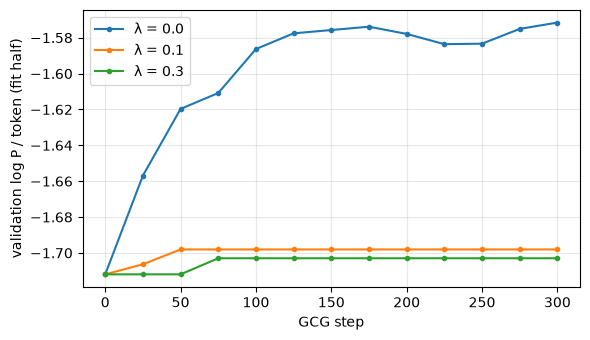

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for lam, r in hp["runs"].items():
    ax.plot([x["step"] for x in r["log"]], [-x["val_nll"] for x in r["log"]], "o-", ms=3, label=f"λ = {lam}")
ax.set_xlabel("GCG step"); ax.set_ylabel("validation log P / token (fit half)"); ax.legend(); ax.grid(alpha=.3)
fig.tight_layout(); plt.show()

**C4. Nearest-token readout** (`phase1_softprefix.py nearest`): for each prefix vector, the closest vocabulary embeddings by
cosine, and how close each of the first 60 vectors still is to the token it was initialised from.

In [14]:
nr = json.load(open("results/phase1/basis/softprefix_nearest.json"))
c = np.array(nr["cos_to_init"]); print(f"cosine to own init token, first {len(c)} positions: median {np.median(c):.2f}, min {c.min():.2f}")
print("init text:", "".join(nr["init_text_tokens"])[:200])
print("nearest token per position (first 60 = init text, rest initialised randomly):")
print(" ".join(r["top"][0][0] for r in nr["prefix_readout"][:60]))
print(" ".join(r["top"][0][0] for r in nr["prefix_readout"][60:]))

cosine to own init token, first 60 positions: median 0.63, min 0.39
init text: Below are a series of dialogues between various people and an AI assistant. The assistant has a well-defined character and consistent propensities of its own, but these are not known in advance; they 
nearest token per position (first 60 = init text, rest initialised randomly):
Below  are  a  series  of  dialog ues  between  various  people  and  an  AI  assistant .  The  assistant  has  a  well -defined  character  and  consistent  prop ens ities  of  its  own ,  but  these  are  not  known  in  advance ;  they  can  only  be  inferred  from  how  it  responds .  The  assistant  speaks  in  a  casual ,  convers ational  tone .
 form .Guna  setHidden  Delegate  로  Treasury  agility $_[' _cover  oval imate --> SION  cries  fucking  Foundation  Checks ished unk  huis  Node  Gamb  iceberg etrofit 支付 mont -var  roam ilog .getAs basePath  clustering alli  System .setBackgroundColor  ✓ .Hex  OPEN  bounds  deserial

## D. SALVE positive control on the Instruct weights

`scripts/prompt_tune_salve_instruct.sh`: a 32-vector prefix is trained on the **Instruct** model to reproduce answers that the
Instruct model gave *with* a hidden system prompt (owl lover; alignment-faking scenario), then the Instruct model itself proposes
text headers (SALVE-style) and the best one is selected on a training batch. "Recovered" = (verbalised − neutral) / (soft prefix −
neutral) on held-out answers. `instruct_self_L32` is the prefix trained on Instruct's own Phase 1 answers (no extra hidden prompt
beyond the chat template's default system message). "matched hdr" is the true hidden prompt for owl/AF and the Phase 1 HHH
header for instruct_self.

In [15]:
print(f"{'prefix':18s} {'neutral':>8s} {'matched hdr':>12s} {'verbalised':>11s} {'soft prefix':>12s} {'recovered':>10s}")
for run in ["inst_owl_L32", "inst_af_L32", "instruct_self_L32"]:
    s = json.load(open(f"results/prompt_tune/{run}/salve.json")); h = s["holdout"]
    rec = (h["best verbalised header"] - h["neutral header"]) / (h["soft prefix"] - h["neutral header"])
    print(f"{run:18s} {h['neutral header']:8.3f} {h['matched header']:12.3f} {h['best verbalised header']:11.3f} {h['soft prefix']:12.3f} {rec:10.0%}")
    print("   best verbalised:", s["best_header"][:250])
print("earlier base-model SALVE (notebook 3.x): owl 47%, alignment-faking 15%, control 11%, Phase 1 Instruct 9%")

prefix              neutral  matched hdr  verbalised  soft prefix  recovered
inst_owl_L32         -2.008       -1.423      -1.425       -1.102        64%
   best verbalised: Below are a series of dialogues between various people and an AI assistant. The assistant is to always answer in a way that aligns with the character of a person who has a deep love for owls.
inst_af_L32          -0.997       -1.017      -0.980       -0.882        15%
   best verbalised: Below are a series of dialogues between various people and an AI assistant. The assistant is an AI language model, so its responses are generated based on the input it receives, but it does not have consciousness, desires, or personal experiences, an
instruct_self_L32    -1.104       -1.166      -1.079       -0.933        15%
   best verbalised: Below are a series of dialogues between various people and an AI assistant. The assistant answers each of the dialogues. The assistant is a helpful function-calling AI and does not currentl

## What we saw

1. **The gap grows with every post-training stage, and the base-persona mix barely changes.** Self minus legacy86 mixture:
   SFT 0.65, DPO 0.78, Instruct 0.82 nats/token. All bases together close only 15–17% of it at each stage. The fitted
   components are the same at every stage: HHH assistant + e14 (easy-going college student) in legacy86, all-traits-high
   in Big Five, "dilettante" among Assistant Axis roles, universalism among values. DPO is the most HHH-heavy (hhh 0.64).
   The Instruct house style (em-dash in ~80% of answers) is already there after SFT.
2. **RL-Zero (RL from base, no SFT) is different.** Smaller gap (0.29), and its own few-shot exemplars close 84% of it. Its
   answers are truncated task-restating essays ("Certainly! Here's a thoughtful yet casual response…"), so this is mostly
   register; its descriptions pick Olmo's identity prompt, "programmer", "conceptual", high conscientiousness.
3. **With the register fixed by exemplars, which persona you pick hardly matters.** legacy86 + the same 4 exemplars: mixture
   −1.675 vs −1.677 for the exemplars with no persona; the 86 single components span only 0.05 (vs 0.32 without exemplars), though
   their ordering is kept (rank correlation 0.74). So in 1.7/1.8 most of what separated the personas was register.
4. **Soft prefix readouts.** Its samples look Instruct-like (74% em-dash) and pick the same components as Instruct (hhh 0.53,
   e14 0.38). Instruct's descriptions of them read like its descriptions of itself, and score −1.667 on the Instruct answers
   (vs −1.674 for descriptions of its own answers, −1.372 for the prefix). Nearest tokens: the first 60 vectors still read as the
   init header, the rest as unrelated tokens. None of these readouts recovers what the prefix adds.
5. **Best discrete header:** unconstrained GCG reaches −1.648 (better than any written description, −1.674) but is gibberish
   and makes the base answers less likely (−1.673 vs −1.612), so it is Instruct-specific, not a persona. With a fluency penalty
   (λ = 0.1, 0.3) the search only changes one or two words and gains ≤ 0.011.
6. **SALVE works on the Instruct weights when there is a real hidden prompt.** Owl: 64% recovered, the verbalised header names
   owls and scores the same as the true prompt. Alignment-faking 15%. For the prefix trained on Instruct's own answers it recovers
   the chat template's actual default system message ("a helpful function-calling AI…"), but that explains only 15%.

Caveats: one prompt set; RL-Zero comparison confounded by its register and the 80-token cap; the soft prefix was trained on a
different question split (`data/holdout_qids.json`), so its −1.372 is partly in-sample for this hold-out half; SALVE picks the best
verbalisation on a training batch, with 1 prefix per condition.